First 5 rows of fMRI ROI dataset:
   time_sec condition  Visual_Cortex  Prefrontal_Cortex  Hippocampus  \
0       0.0      Rest       0.076179          -0.255874    -0.192909   
1       2.0      Rest      -0.259996           0.044819     0.019196   
2       4.0      Rest       0.187613           0.054999    -0.307233   
3       6.0      Rest       0.235141           0.339797    -0.204542   
4       8.0      Rest      -0.487759           0.208778     0.624202   

   Motor_Cortex  Amygdala  
0     -0.038131  0.044616  
1      0.095848  0.286643  
2      0.249956  0.018304  
3     -0.264634  0.116155  
4     -0.031252 -0.011357  

Mean BOLD signal by Condition:
             Visual_Cortex  Prefrontal_Cortex  Hippocampus  Motor_Cortex  \
condition                                                                  
Memory_Task          0.275              1.510        1.404        -0.036   
Rest                -0.032             -0.011        0.022         0.023   
Visual_Task          1.428   

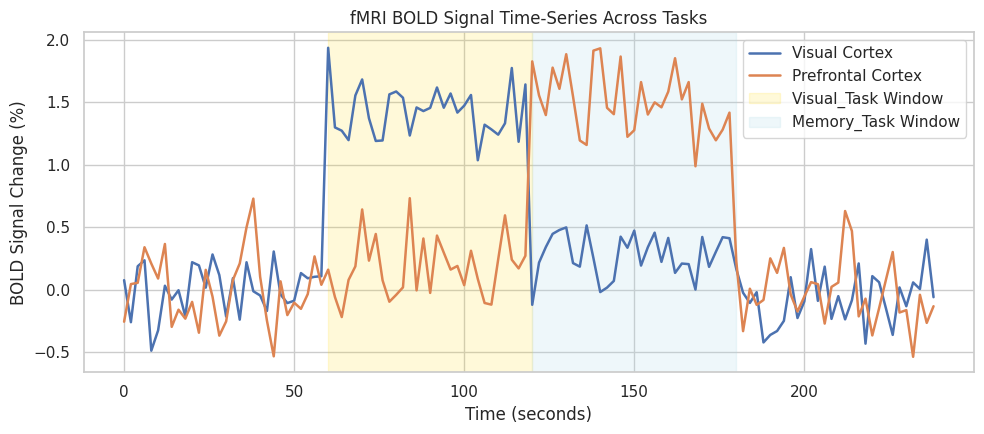

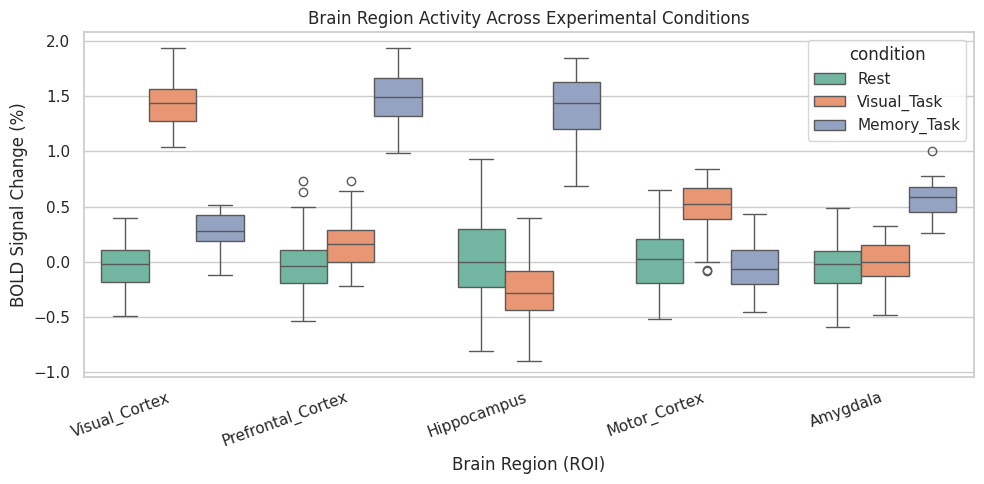

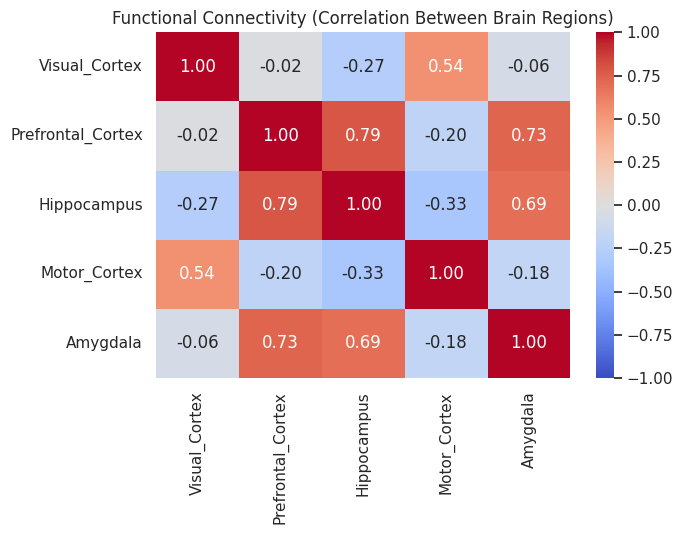

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)


# 1. CREATE / LOAD fMRI ROI TIME-SERIES DATA

# 120 time points (TRs), 5 brain regions (ROIs)

n_timepoints = 120
time_sec = np.arange(n_timepoints) * 2.0  # Assuming TR = 2 seconds

# Experimental condition blocks across time
conditions = np.array(
    ["Rest"] * 30
    + ["Visual_Task"] * 30
    + ["Memory_Task"] * 30
    + ["Rest"] * 30
)

# Simulate BOLD fMRI signal (% signal change) for each brain region
visual_cortex = (
    rng.normal(0, 0.25, n_timepoints)
    + np.where(conditions == "Visual_Task", 1.4, 0.0)
    + np.where(conditions == "Memory_Task", 0.3, 0.0)
)

prefrontal_cortex = (
    rng.normal(0, 0.25, n_timepoints)
    + np.where(conditions == "Memory_Task", 1.5, 0.0)
    + np.where(conditions == "Visual_Task", 0.2, 0.0)
)

hippocampus = (
    rng.normal(0, 0.22, n_timepoints)
    + np.where(conditions == "Memory_Task", 1.1, 0.0)
    + 0.4 * np.sin(time_sec / 20.0)
)

motor_cortex = rng.normal(0, 0.25, n_timepoints) + np.where(
    conditions == "Visual_Task", 0.5, 0.0
)

amygdala = rng.normal(0, 0.20, n_timepoints) + np.where(
    conditions == "Memory_Task", 0.6, 0.0
)

df = pd.DataFrame({
    "time_sec": time_sec,
    "condition": conditions,
    "Visual_Cortex": visual_cortex,
    "Prefrontal_Cortex": prefrontal_cortex,
    "Hippocampus": hippocampus,
    "Motor_Cortex": motor_cortex,
    "Amygdala": amygdala,
})

print("First 5 rows of fMRI ROI dataset:")
print(df.head())

print("\nMean BOLD signal by Condition:")
roi_cols = [
    "Visual_Cortex",
    "Prefrontal_Cortex",
    "Hippocampus",
    "Motor_Cortex",
    "Amygdala",
]
print(df.groupby("condition")[roi_cols].mean().round(3))


# 2. NUMPY STATS (MEAN, STD, Z-SCORE)

# Normalize each ROI signal across time using z-score: (x - mean) / std

z_scores = df[roi_cols].apply(
    lambda col: (col - np.mean(col)) / np.std(col)
)
print("Max z-score per brain region:")
print(z_scores.max().round(2))


# 3. VISUALIZATIONS (MATPLOTLIB + SEABORN)

# Chart 1: fMRI BOLD Time-Series across Time (Matplotlib)

plt.figure(figsize=(10, 4.5))
plt.plot(
    df["time_sec"],
    df["Visual_Cortex"],
    label="Visual Cortex",
    linewidth=1.8,
)
plt.plot(
    df["time_sec"],
    df["Prefrontal_Cortex"],
    label="Prefrontal Cortex",
    linewidth=1.8,
)
plt.axvspan(60, 120, color="gold", alpha=0.15, label="Visual_Task Window")
plt.axvspan(120, 180, color="lightblue", alpha=0.2, label="Memory_Task Window")
plt.title("fMRI BOLD Signal Time-Series Across Tasks")
plt.xlabel("Time (seconds)")
plt.ylabel("BOLD Signal Change (%)")
plt.legend()
plt.tight_layout()
plt.show()

# Chart 2: Brain Activation by Condition (Seaborn Boxplot)

melted_df = df.melt(
    id_vars=["time_sec", "condition"],
    value_vars=roi_cols,
    var_name="Brain_Region",
    value_name="BOLD_Signal",
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=melted_df,
    x="Brain_Region",
    y="BOLD_Signal",
    hue="condition",
    palette="Set2",
)
plt.xticks(rotation=20, ha="right")
plt.title("Brain Region Activity Across Experimental Conditions")
plt.xlabel("Brain Region (ROI)")
plt.ylabel("BOLD Signal Change (%)")
plt.tight_layout()
plt.show()

# Chart 3: Functional Connectivity Matrix (Seaborn Heatmap)

corr_matrix = df[roi_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Functional Connectivity (Correlation Between Brain Regions)")
plt.tight_layout()
plt.show()